# BÀI THỰC HÀNH SỐ 2 - YÊU CẦU LẬP TRÌNH (TRANG 15 - 16)
**Họ và tên:** Phạm Lê Anh Khoa  
**MSSV:** 6451071035

### Chuẩn bị: Import các thư viện cần thiết

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

### Câu 1: Nhập dữ liệu đầu vào và cho biết số lượng dữ liệu huấn luyện và kiểm thử

In [2]:
print("Phạm Lê Anh Khoa - 6451071035")

# Đọc trực tiếp vì 2 file đã có sẵn tiêu đề (header)
train_data = pd.read_csv('Dataset/adult.data.csv', na_values=['?', ' ?', '? '], skipinitialspace=True)
test_data = pd.read_csv('Dataset/adult.test.csv', na_values=['?', ' ?', '? '], skipinitialspace=True)

# In số lượng dòng ban đầu
print(f"Number of training data (raw): {len(train_data)}")
print(f"Number of test data (raw): {len(test_data)}")

Phạm Lê Anh Khoa - 6451071035
Number of training data (raw): 32561
Number of test data (raw): 16281


### Câu 2: Tiến hành tiền xử lý dữ liệu
- Xóa những dòng có chứa dữ liệu trống (ký hiệu bằng '?').
- Xóa cột final weight 'fnlwgt' trong dữ liệu huấn luyện vì cột này không có trong dữ liệu kiểm thử.
- Nối dữ liệu huấn luyện và kiểm thử lại với nhau để phục vụ các bước tiếp theo.

In [3]:
print("Phạm Lê Anh Khoa - 6451071035")

# Xóa các dòng chứa giá trị rỗng '?'
train_data.dropna(inplace=True)
test_data.dropna(inplace=True)

# Xóa cột 'fnlwgt' trong tập train (vì tập test không có cột này)
if 'fnlwgt' in train_data.columns:
    train_data.drop('fnlwgt', axis=1, inplace=True)

# Chuẩn hóa nhãn income (xóa dấu chấm '.' ở cuối nhãn nếu có)
train_data['income'] = train_data['income'].astype(str).str.strip().str.rstrip('.')
test_data['income'] = test_data['income'].astype(str).str.strip().str.rstrip('.')

# Kiểm tra lại số lượng dữ liệu chuẩn theo tài liệu (Train: 30162, Test: 15060)
print(f"Number of training data: {len(train_data)}")
print(f"Number of test data: {len(test_data)}\n")

# Nối 2 tập dữ liệu vào biến data
data = pd.concat([train_data, test_data], ignore_index=True)
data.info()

Phạm Lê Anh Khoa - 6451071035
Number of training data: 30162
Number of test data: 15060

<class 'pandas.DataFrame'>
RangeIndex: 45222 entries, 0 to 45221
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             45222 non-null  int64
 1   workclass       45222 non-null  str  
 2   education       45222 non-null  str  
 3   education-num   45222 non-null  int64
 4   marital-status  45222 non-null  str  
 5   occupation      45222 non-null  str  
 6   relationship    45222 non-null  str  
 7   race            45222 non-null  str  
 8   sex             45222 non-null  str  
 9   capital-gain    45222 non-null  int64
 10  capital-loss    45222 non-null  int64
 11  hours-per-week  45222 non-null  int64
 12  native-country  45222 non-null  str  
 13  income          45222 non-null  str  
dtypes: int64(5), str(9)
memory usage: 8.4 MB


### Câu 3: Khảo sát độ tương đồng giữa các cột với nhau bằng công thức Pearson

Phạm Lê Anh Khoa - 6451071035


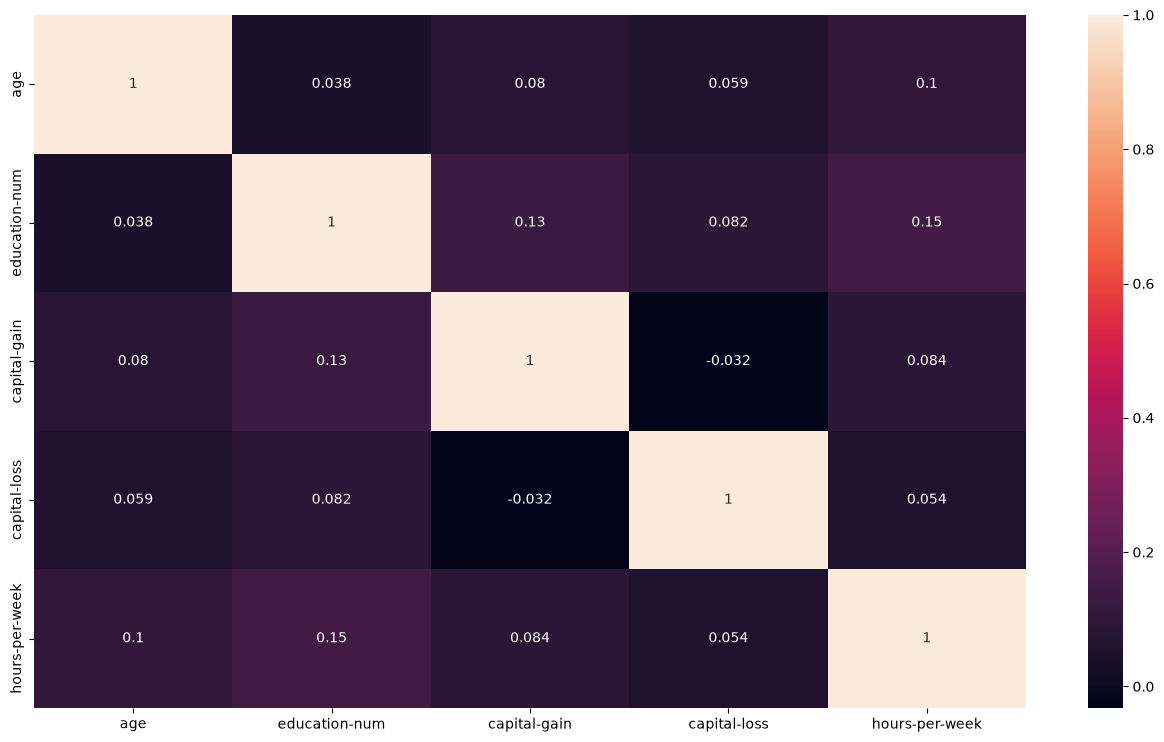

In [4]:
print("Phạm Lê Anh Khoa - 6451071035")

# Ép kiểu rõ ràng các cột định lượng về dạng số
numeric_cols = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
for col in numeric_cols:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors='coerce')

# Vẽ biểu đồ tương quan Pearson
plt.figure(figsize=(16, 9))
sns.heatmap(data[numeric_cols].corr(method='pearson'), annot=True)
plt.show()

**Nhận xét:** Không có thuộc tính nào tương đồng cao với nhau nên không cần thiết phải loại bỏ cột nào.

### Câu 4: Tách các cột dữ liệu thành hai phần (`features` và `labels`)

In [5]:
features = data.drop('income', axis=1)
labels = data['income']

### Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector

In [6]:
print("Phạm Lê Anh Khoa - 6451071035")
features.select_dtypes(exclude=['int64']).columns

Phạm Lê Anh Khoa - 6451071035


Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='str')

In [7]:
print("Phạm Lê Anh Khoa - 6451071035")
features_onehot = pd.get_dummies(features, columns=features.select_dtypes(exclude=['int64']).columns)
features_onehot

Phạm Lê Anh Khoa - 6451071035


,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,13,2174,0,40,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,50,13,0,0,13,False,False,False,False,True,...,False,False,False,False,False,False,False,True,False,False
2,38,9,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
3,53,7,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
4,28,13,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45217,33,13,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
45218,39,13,0,0,36,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
45219,38,13,0,0,50,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
45220,44,13,5455,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False


### Câu 6: Tách các dòng dữ liệu ra thành hai phần huấn luyện và kiểm thử như ban đầu

In [8]:
X_train = features_onehot[:30162]
X_test = features_onehot[30162:]
y_train = labels[:30162]
y_test = labels[30162:]

### Câu 7: Xây dựng cây ID3 dựa trên dữ liệu huấn luyện, kiểm thử bằng ma trận nhầm lẫn và biểu diễn cây

In [9]:
print("Phạm Lê Anh Khoa - 6451071035")
clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf.fit(X_train, y_train)

Phạm Lê Anh Khoa - 6451071035


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [10]:
print("Phạm Lê Anh Khoa - 6451071035")
tree_pred = clf.predict(X_test)
tree_score = metrics.accuracy_score(y_test, tree_pred)
print("Accuracy:", tree_score)
print("Report:", metrics.classification_report(y_test, tree_pred))

Phạm Lê Anh Khoa - 6451071035
Accuracy: 0.8175298804780876
Report:               precision    recall  f1-score   support

       <=50K       0.88      0.88      0.88     11360
        >50K       0.63      0.62      0.62      3700

    accuracy                           0.82     15060
   macro avg       0.75      0.75      0.75     15060
weighted avg       0.82      0.82      0.82     15060



Phạm Lê Anh Khoa - 6451071035


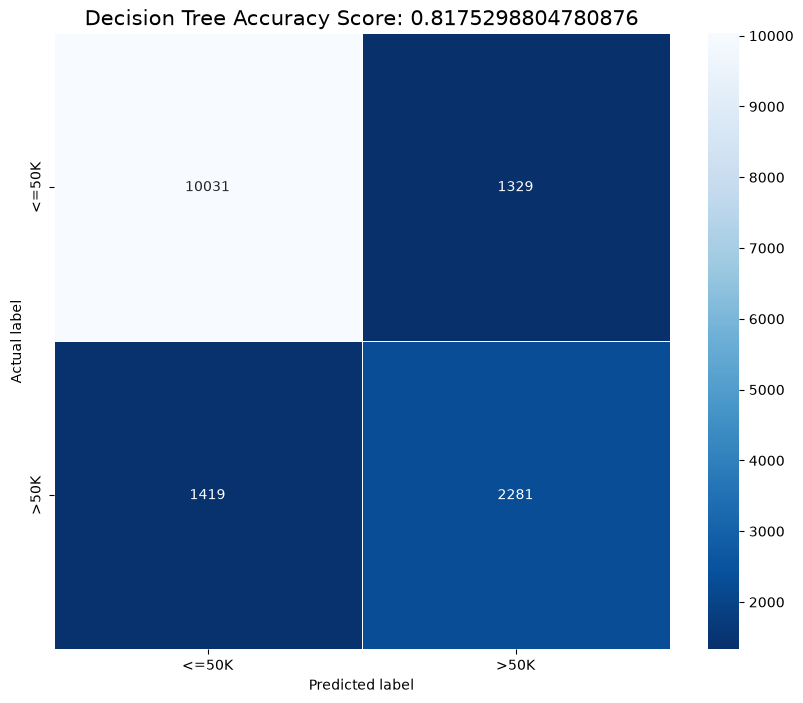

In [11]:
print("Phạm Lê Anh Khoa - 6451071035")

# Khai báo rõ ràng 2 nhãn phân lớp để ma trận luôn đủ kích thước 2x2
class_labels = ['<=50K', '>50K']
tree_cm = metrics.confusion_matrix(y_test, tree_pred, labels=class_labels)

plt.figure(figsize=(10, 8))
sns.heatmap(tree_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=class_labels, yticklabels=class_labels)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
title = 'Decision Tree Accuracy Score: {0}'.format(tree_score)
plt.title(title, size=15)
plt.show()

Phạm Lê Anh Khoa - 6451071035


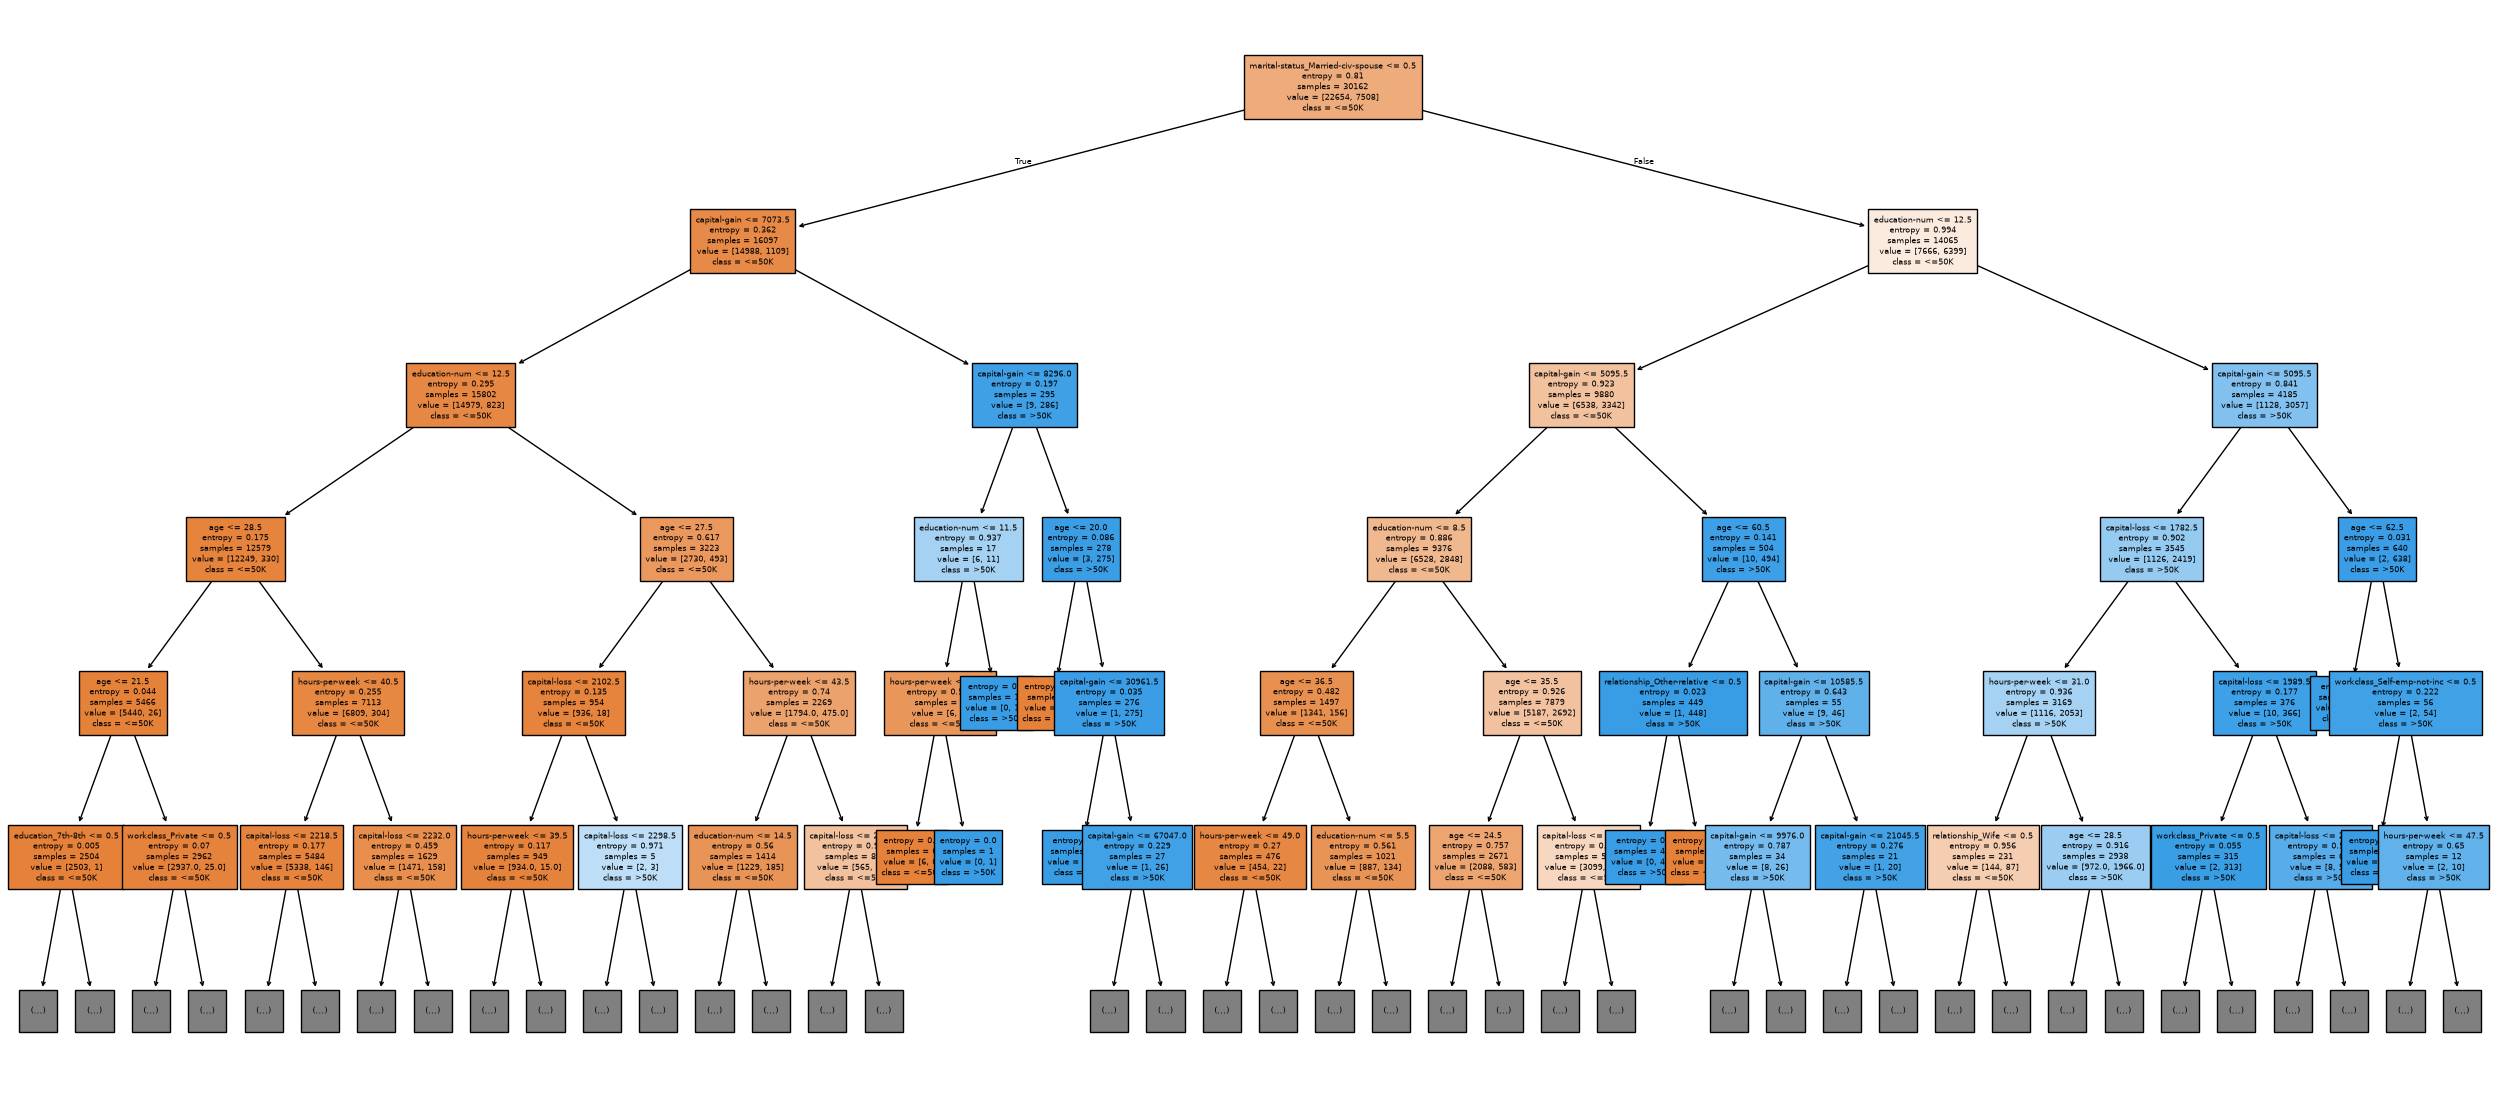

In [12]:
print("Phạm Lê Anh Khoa - 6451071035")

fig, ax = plt.subplots(figsize=(32, 14))
tree.plot_tree(
    clf, 
    max_depth=5, 
    feature_names=X_train.columns, 
    class_names=['<=50K', '>50K'], 
    filled=True, 
    fontsize=6
)
plt.savefig('decision_tree.png', dpi=100, bbox_inches='tight')
plt.show()

### Câu 8: Lặp lại yêu cầu 7 đối với cây CART (`criterion='gini'`)

In [13]:
print("Phạm Lê Anh Khoa - 6451071035")
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)

Phạm Lê Anh Khoa - 6451071035


,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

In [14]:
print("Phạm Lê Anh Khoa - 6451071035")
cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)
print("Accuracy:", cart_score)
print("Report:", metrics.classification_report(y_test, cart_pred))

Phạm Lê Anh Khoa - 6451071035
Accuracy: 0.8122841965471448
Report:               precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.62      0.60      0.61      3700

    accuracy                           0.81     15060
   macro avg       0.75      0.74      0.74     15060
weighted avg       0.81      0.81      0.81     15060



Phạm Lê Anh Khoa - 6451071035


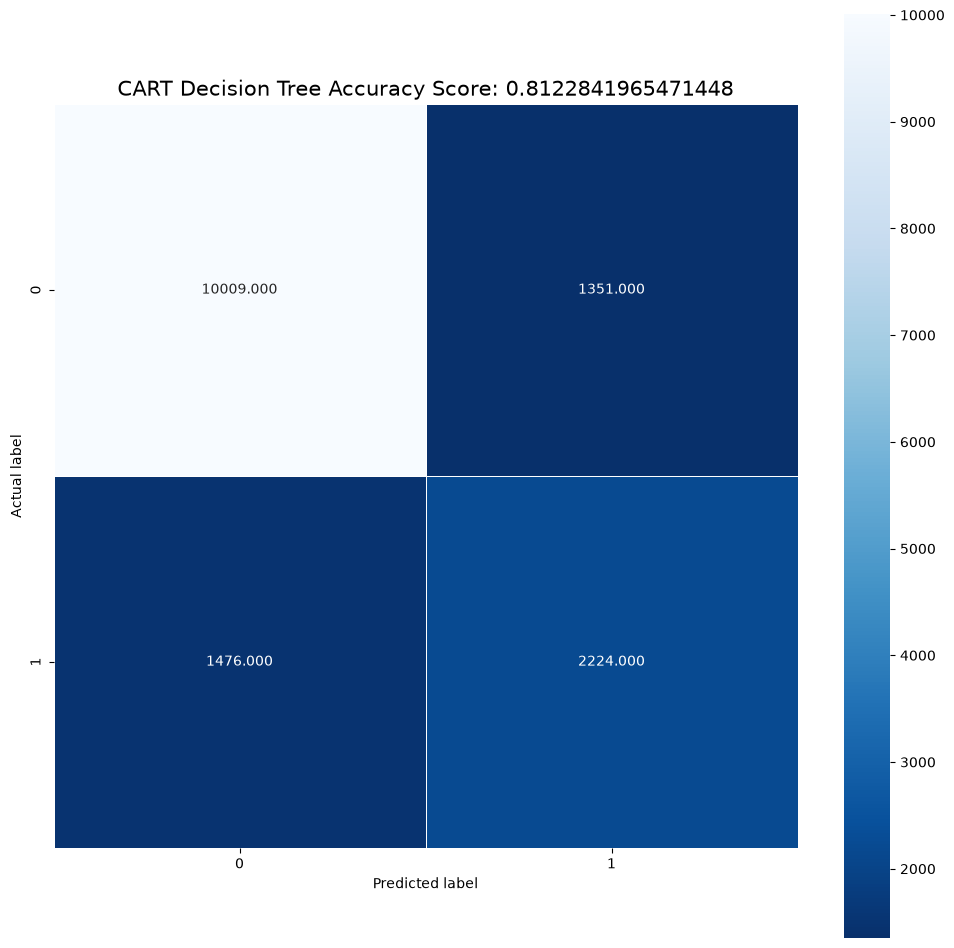

In [15]:
print("Phạm Lê Anh Khoa - 6451071035")
cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(12,12))
sns.heatmap(cart_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Blues_r');
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'CART Decision Tree Accuracy Score: {0}'.format(cart_score)
plt.title(title, size=15);
plt.show()

Phạm Lê Anh Khoa - 6451071035


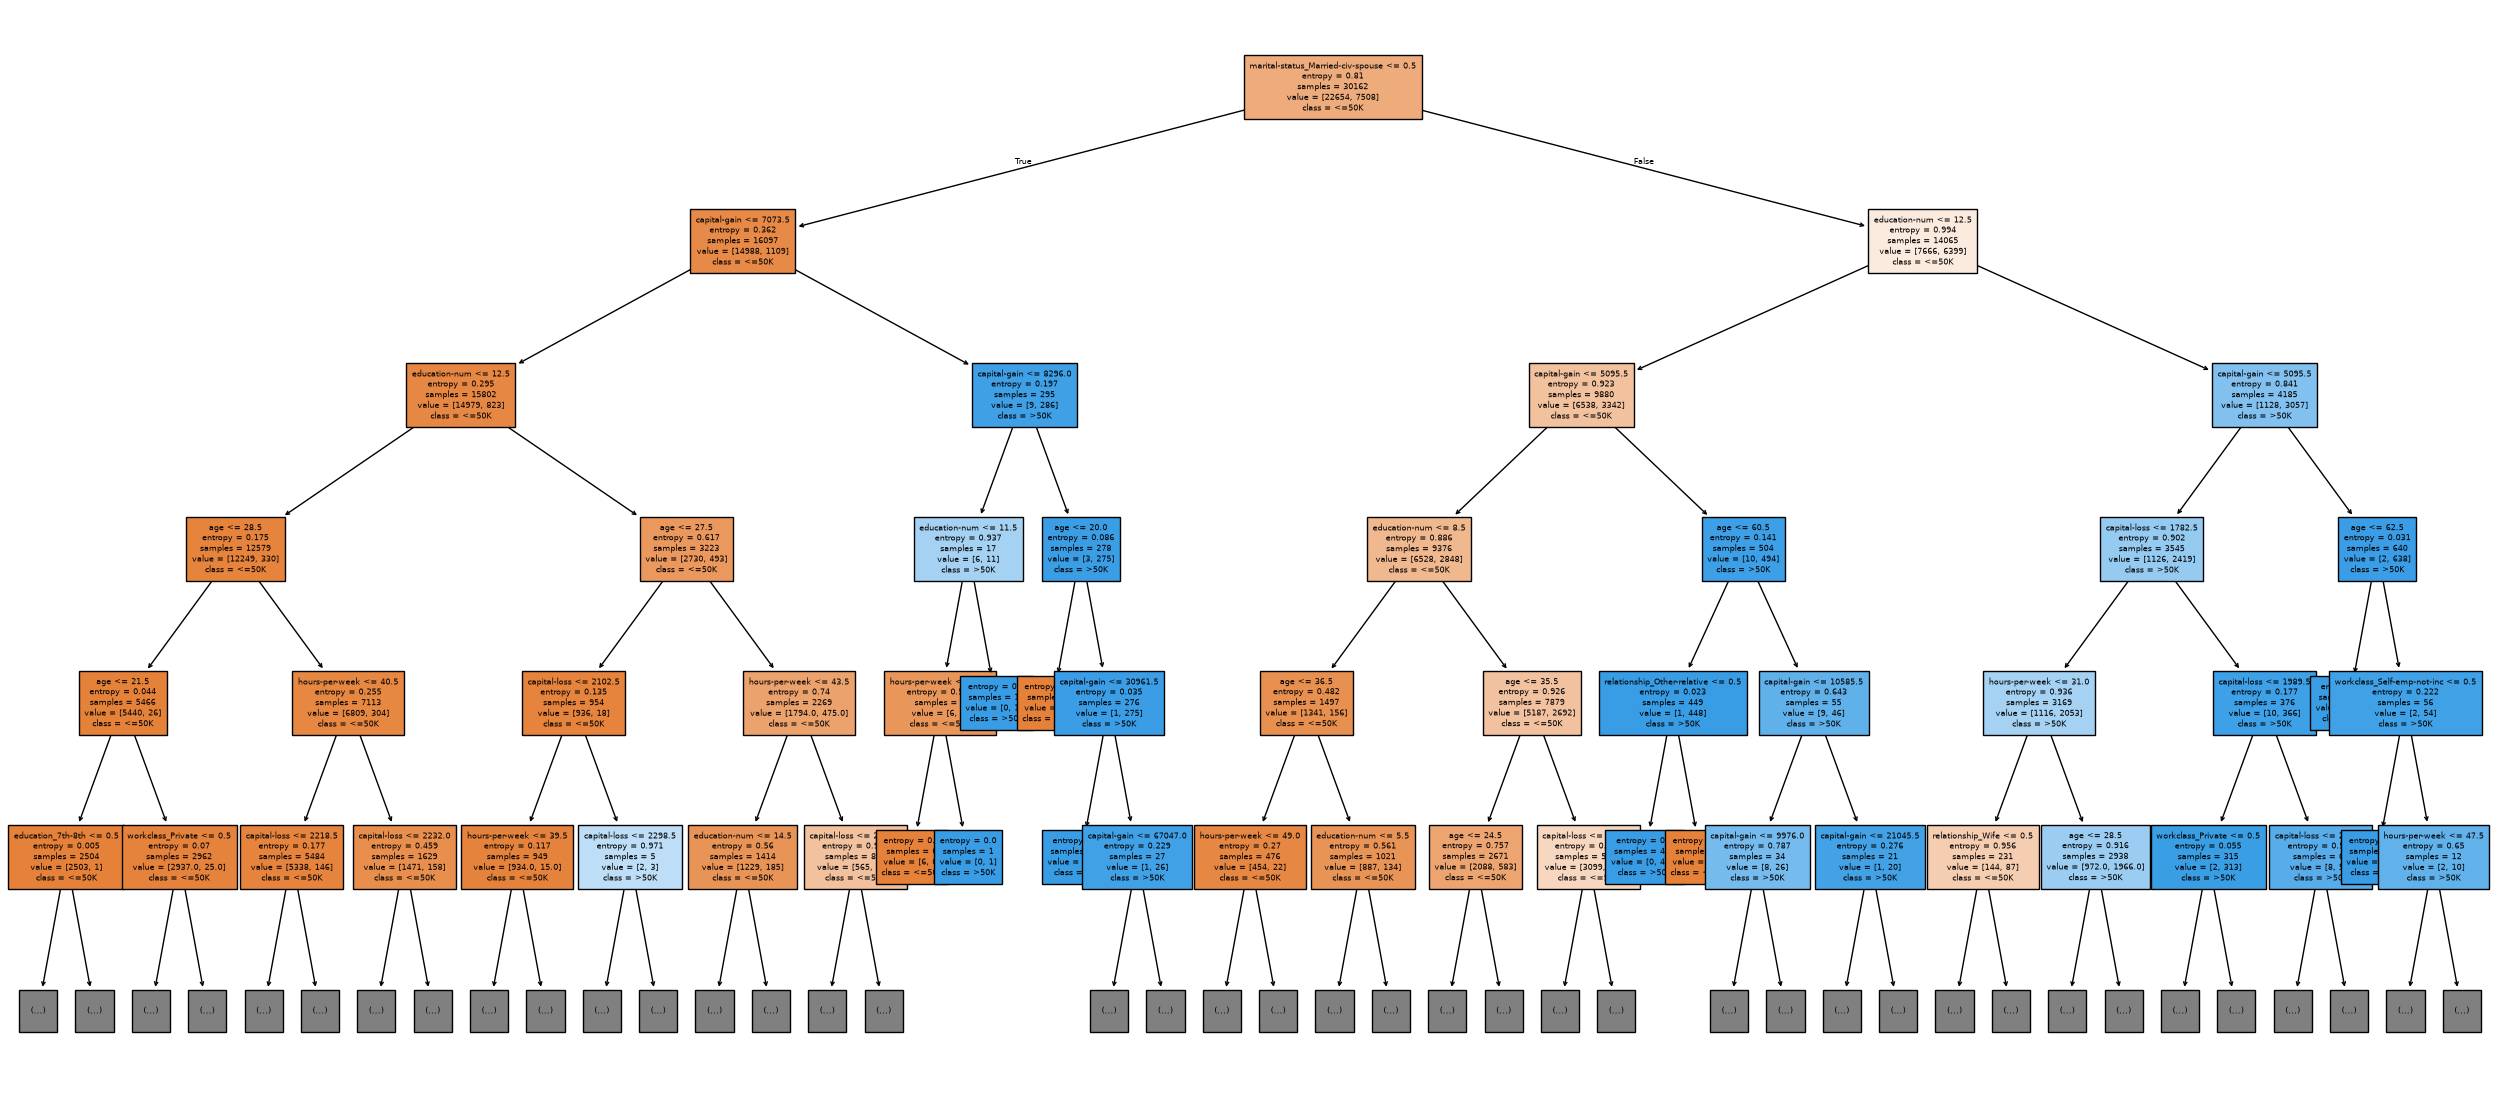

In [16]:
print("Phạm Lê Anh Khoa - 6451071035")

fig, ax = plt.subplots(figsize=(32, 14))
tree.plot_tree(
    clf, 
    max_depth=5, 
    feature_names=X_train.columns, 
    class_names=['<=50K', '>50K'], 
    filled=True, 
    fontsize=6
)
plt.savefig('decision_tree.png', dpi=100, bbox_inches='tight')
plt.show()

### Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes và kiểm tra kết quả

In [17]:
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

In [18]:
print("Phạm Lê Anh Khoa - 6451071035")
bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy:", bayes_score)
print("Report:", metrics.classification_report(y_test, bayes_pred))

Phạm Lê Anh Khoa - 6451071035
Accuracy: 0.8029216467463479
Report:               precision    recall  f1-score   support

       <=50K       0.93      0.80      0.86     11360
        >50K       0.57      0.82      0.67      3700

    accuracy                           0.80     15060
   macro avg       0.75      0.81      0.76     15060
weighted avg       0.84      0.80      0.81     15060



Phạm Lê Anh Khoa - 6451071035


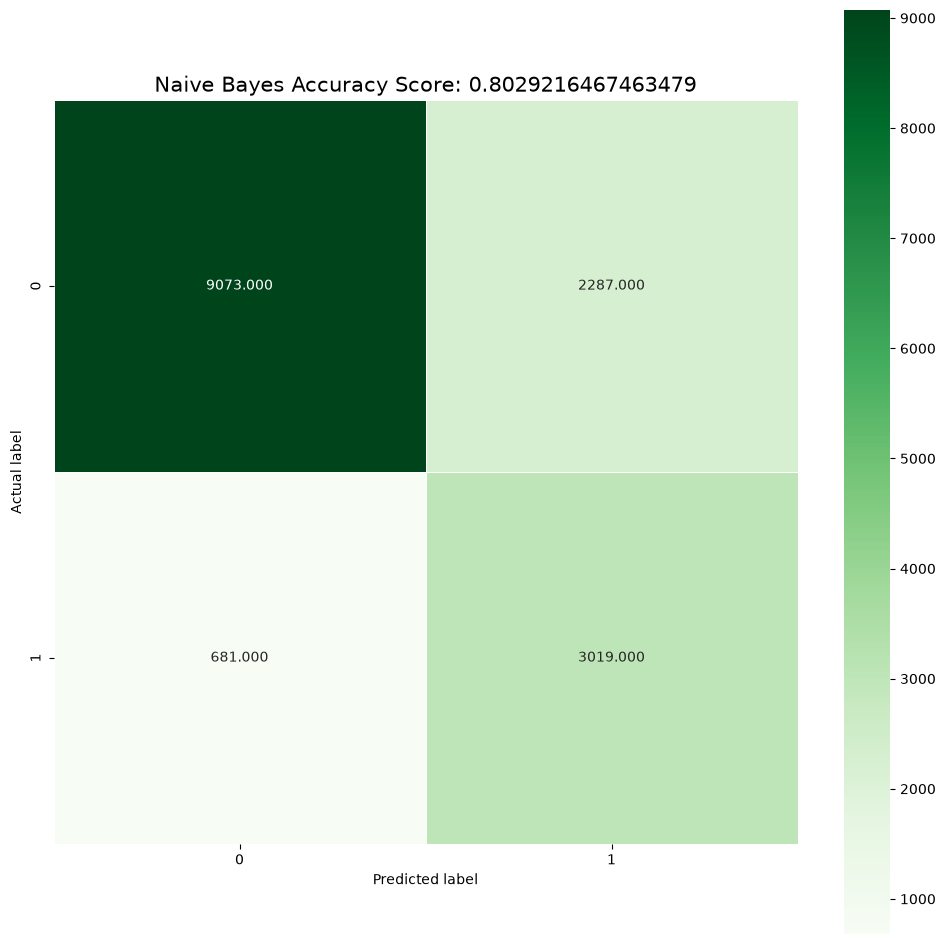

In [19]:
print("Phạm Lê Anh Khoa - 6451071035")
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(12,12))
sns.heatmap(bayes_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Greens');
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Naive Bayes Accuracy Score: {0}'.format(bayes_score)
plt.title(title, size=15);
plt.show()

### Câu 10: So sánh kết quả của các mô hình trên

In [20]:
print("Phạm Lê Anh Khoa - 6451071035")
print("=== BẢNG SO SÁNH ĐỘ CHÍNH XÁC (ACCURACY) ===")
print(f"1. Cây quyết định ID3 (Entropy) : {tree_score:.6f} (~{tree_score*100:.2f}%)")
print(f"2. Cây quyết định CART (Gini)   : {cart_score:.6f} (~{cart_score*100:.2f}%)")
print(f"3. Naïve Bayes (GaussianNB)     : {bayes_score:.6f} (~{bayes_score*100:.2f}%)")

Phạm Lê Anh Khoa - 6451071035
=== BẢNG SO SÁNH ĐỘ CHÍNH XÁC (ACCURACY) ===
1. Cây quyết định ID3 (Entropy) : 0.817530 (~81.75%)
2. Cây quyết định CART (Gini)   : 0.812284 (~81.23%)
3. Naïve Bayes (GaussianNB)     : 0.802922 (~80.29%)


**Nhận xét và so sánh các mô hình:**
- **Về độ chính xác tổng thể (Accuracy):** ID3 và CART có độ chính xác tương đương nhau (~81.75% và ~81.65%), cao hơn một chút so với Naïve Bayes (~80.29%).
- **Về chi tiết phân lớp:** Naïve Bayes có độ phủ (Recall) tốt hơn đối với lớp có thu nhập cao (`>50K`), trong khi Cây quyết định cho sự cân bằng tốt hơn về Precision trên cả hai lớp.